# Modelado predictivo de las pruebas Saber Pro 2020–2022 (Colab)

Proyecto de grado — Especialización en Analítica de Datos (CUN). Este cuaderno reproduce y muestra la fase de **modelado y evaluación** (CRISP-DM):

1. Pipeline sin fuga de información: imputación C1 y codificaciones ajustadas solo con 2020–2021 (467.356 registros); 2022 (193.356) solo se transforma.
2. Batería de 10 modelos supervisados con optimización de hiperparámetros y selección algorítmica de variables.
3. Métricas por pliegue de validación cruzada, prueba 2022, pruebas de significancia e intervalos de confianza.
4. Ablación, SHAP y verificación del criterio de equidad.

**Cómo usarlo.** Por defecto el cuaderno **muestra los resultados ya calculados** del repositorio (se abre en segundos). Para volver a ejecutar el pipeline cambie `EJECUTAR_PIPELINE = True` en la celda 2: la descarga y la limpieza toman unos minutos y la verificación rápida (`--rapido`, submuestra y 3 modelos) otros pocos; el entrenamiento completo (`08`, ~1,5 h) y el análisis final (`09`, ~20 min) se ejecutan con las celdas opcionales del final.

Los datos son abiertos (ICFES, datos.gov.co, `u37r-hjmu`) y no se versionan en el repositorio; se descargan con el script `01`.

In [1]:
import os, sys, subprocess
from pathlib import Path

EJECUTAR_PIPELINE = False          # True: descarga datos y reejecuta limpieza + verificación rápida del modelado
URL_REPO = "https://github.com/Yohr26/saberpro-analitica.git"

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    if not Path("saberpro-analitica").exists():
        # Si el repositorio es privado, Colab pedirá credenciales: use un token personal con permiso de lectura.
        r = subprocess.run(["git", "clone", "--depth", "1", URL_REPO], capture_output=True, text=True)
        if r.returncode != 0:
            from getpass import getpass
            token = getpass("Token de GitHub (solo lectura): ")
            subprocess.run(["git", "clone", "--depth", "1", URL_REPO.replace("https://", f"https://{token}@")], check=True)
    os.chdir("saberpro-analitica")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    # ejecucion local: subir hasta la raiz del repositorio (carpeta que contiene src/ y reports/)
    while not (Path.cwd() / "src").exists() and Path.cwd().parent != Path.cwd():
        os.chdir(Path.cwd().parent)
print("Directorio de trabajo:", Path.cwd().name)

Directorio de trabajo: saberpro-analitica


In [2]:
if EJECUTAR_PIPELINE:
    for paso in ["src/01_descargar_datos.py", "src/02_etl_limpieza.py", "src/08_modelado_entrenamiento.py --rapido"]:
        print(">>", paso)
        r = subprocess.run([sys.executable, "-u", *paso.split()], capture_output=True, text=True)
        print(r.stdout[-1500:] or r.stderr[-1500:])
else:
    print("Se muestran los resultados ya calculados (reports/tables y reports/figures).")

Se muestran los resultados ya calculados (reports/tables y reports/figures).


## 1. Diseño: pipeline sin fuga y partición temporal

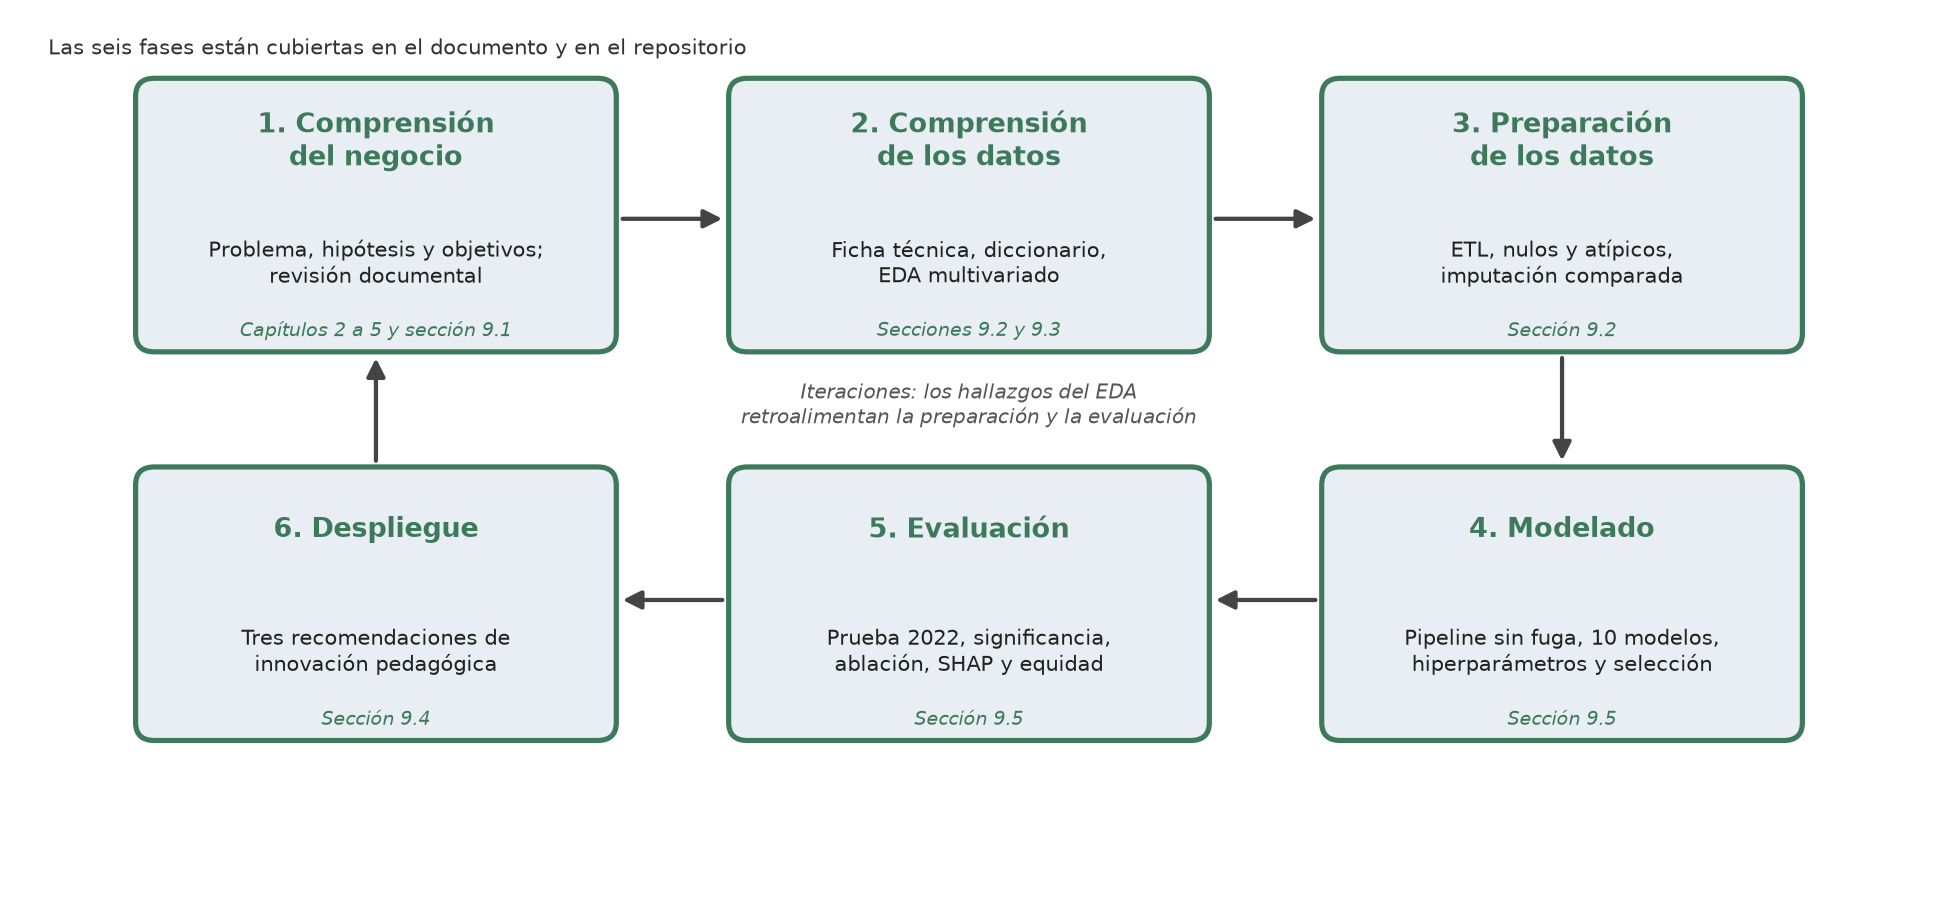

Pipeline: ImputadorC1 -> ColumnTransformer(OneHot | TargetEncoder(cv) | mediana+escala) -> selector (Lasso/ninguno) -> estimador
Entrenamiento 2020-2021: 467.356 | Prueba 2022: 193.356 | umbral de bajo desempeno = P25 del entrenamiento = 131,0


In [3]:
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200, "display.max_columns", 30)
T, F = Path("reports/tables"), Path("reports/figures")

display(Image(F / "fig_00_crispdm.png", width=760))
print("Pipeline: ImputadorC1 -> ColumnTransformer(OneHot | TargetEncoder(cv) | mediana+escala) -> selector (Lasso/ninguno) -> estimador")
print("Entrenamiento 2020-2021: 467.356 | Prueba 2022: 193.356 | umbral de bajo desempeno = P25 del entrenamiento = 131,0")

## 2. Hiperparámetros elegidos (búsqueda aleatoria, selector de variables incluido)

In [4]:
import json
hp = json.loads((T / "mod_hiperparametros.json").read_text(encoding="utf-8"))
pd.DataFrame([{"modelo": k, "selector": v["selector"], "objetivo_cv": round(v["objetivo_cv"], 4), "parametros": v["params"]} for k, v in hp.items()])

,modelo,selector,objetivo_cv,parametros
0,Ridge,lasso_suave,19.3128,{'alpha': 77.26718477963419}
1,RandomForest,ninguno,18.9537,"{'min_samples_leaf': 20, 'max_features': 0.3, ..."
2,HistGradientBoosting,lasso_suave,18.6459,"{'min_samples_leaf': 200, 'max_leaf_nodes': 31..."
3,LightGBM,lasso_suave,18.6159,"{'subsample': 0.7, 'reg_lambda': 5.0, 'num_lea..."
4,XGBoost,ninguno,18.6069,"{'subsample': 0.9, 'reg_lambda': 10.0, 'n_esti..."
5,Regresión logística,ninguno,-0.7590,{'C': 0.13292918943162169}
6,RandomForest (clasif.),ninguno,-0.7768,"{'min_samples_leaf': 20, 'max_features': 0.3, ..."
7,HistGradientBoosting (clasif.),lasso_suave,-0.7728,"{'min_samples_leaf': 200, 'max_leaf_nodes': 15..."
8,LightGBM (clasif.),lasso_suave,-0.7749,"{'subsample': 0.7, 'reg_lambda': 20.0, 'num_le..."
9,XGBoost (clasif.),ninguno,-0.7833,"{'subsample': 0.9, 'reg_lambda': 10.0, 'n_esti..."


## 3. Métricas por pliegue de validación cruzada (archivos para las pruebas de hipótesis)

conocidas: 65 filas (modelo x pliegue); columnas: ['esquema', 'pliegue', 'modelo', 'tarea', 'n_train', 'n_val', 'RMSE', 'MAE', 'R2', 'AUC', 'AP', 'recall25', 'precision25', 'segundos', 'Brier']
grupos: 65 filas (modelo x pliegue); columnas: ['esquema', 'pliegue', 'modelo', 'tarea', 'n_train', 'n_val', 'RMSE', 'MAE', 'R2', 'AUC', 'AP', 'recall25', 'precision25', 'segundos', 'Brier']


,esquema,modelo,tarea,RMSE_media,RMSE_sd,MAE_media,R2_media,AUC_media,AUC_sd,recall25_media,precision25_media,seg_media
0,conocidas,B0. Media global,linea_base,24.817,0.042,19.998,-0.000,0.500,0.000,0.206,0.204,0.00
1,conocidas,B1. Media por estrato,linea_base,23.578,0.033,18.937,0.097,0.618,0.002,0.345,0.342,0.00
2,conocidas,B3. Media por institución,linea_base,20.417,0.028,16.234,0.323,0.726,0.002,0.434,0.430,0.00
3,conocidas,HistGradientBoosting,regresion,18.559,0.044,14.631,0.441,0.787,0.002,0.520,0.515,78.00
4,conocidas,HistGradientBoosting (clasif.),clasificacion,NaN,NaN,NaN,NaN,0.780,0.002,0.510,0.505,10.26
5,conocidas,LightGBM,regresion,18.521,0.048,14.599,0.443,0.788,0.002,0.521,0.516,61.16
6,conocidas,LightGBM (clasif.),clasificacion,NaN,NaN,NaN,NaN,0.780,0.002,0.511,0.506,4.98
7,conocidas,RandomForest,regresion,18.823,0.024,14.862,0.425,0.781,0.002,0.512,0.507,24.46
8,conocidas,RandomForest (clasif.),clasificacion,NaN,NaN,NaN,NaN,0.782,0.002,0.513,0.509,28.14
9,conocidas,Regresión logística,clasificacion,NaN,NaN,NaN,NaN,0.760,0.002,0.487,0.482,27.78


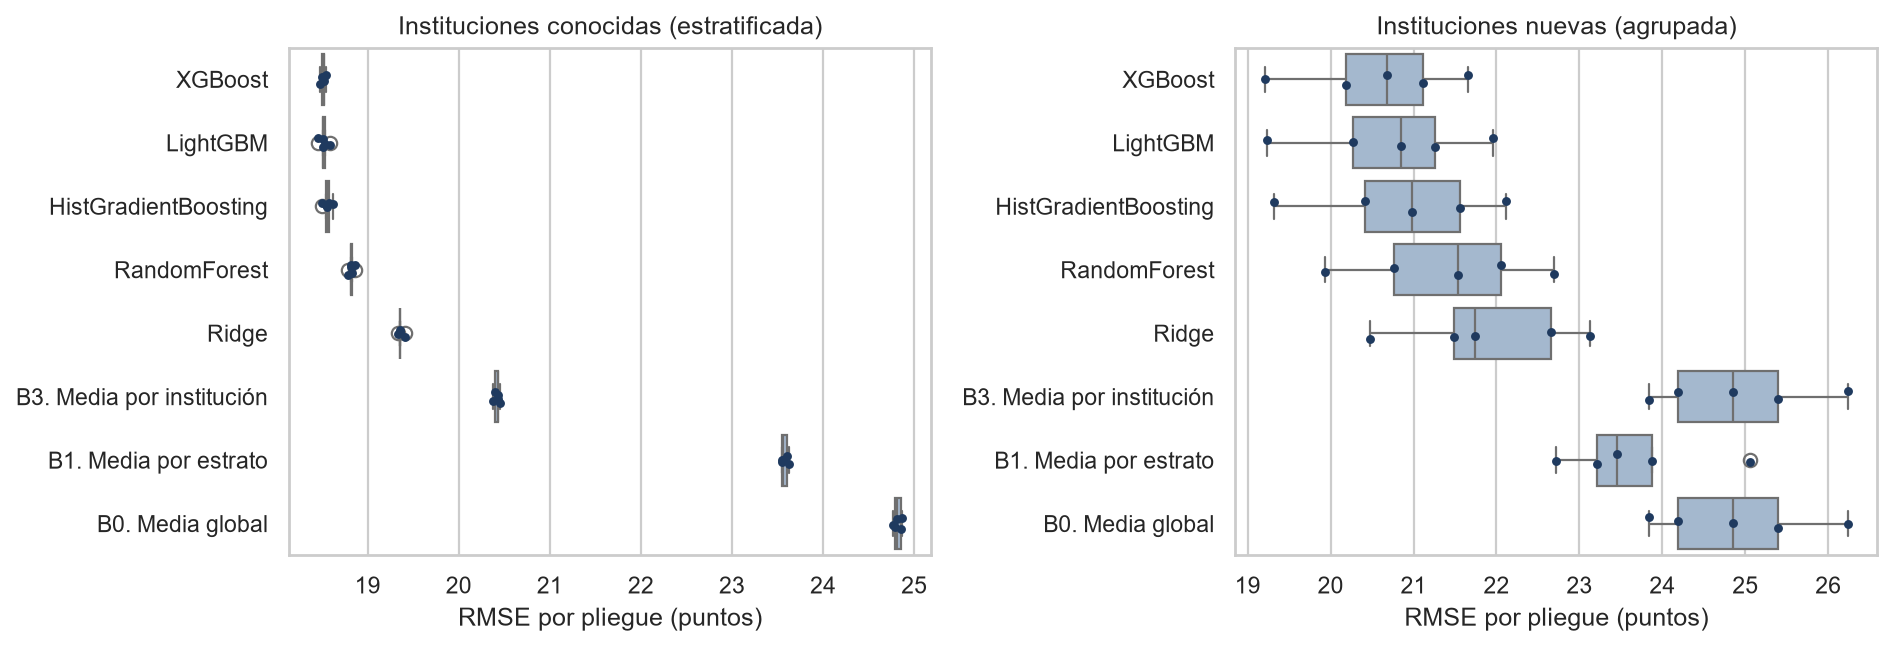

In [5]:
for esquema in ["conocidas", "grupos"]:
    d = pd.read_csv(T / f"mod_cv_pliegues_{esquema}.csv")
    print(f"{esquema}: {len(d)} filas (modelo x pliegue); columnas:", list(d.columns))
display(pd.read_csv(T / "mod_cv_resumen.csv").round(3))
display(Image(F / "mod_cv_rmse_pliegues.png", width=900))

## 4. Significancia: mejor ensamble frente a la línea base institucional (B3)

In [6]:
display(pd.read_csv(T / "mod_significancia_cv.csv").round(4))
display(pd.read_csv(T / "mod_significancia_prueba2022.csv").drop(columns="prueba").round(4))
display(pd.read_csv(T / "mod_test_2022_rmse_ic.csv").round(3))

,esquema,comparacion,dif_RMSE_media,dif_RMSE_sd,t_pareada,p_t_pareada,t_Nadeau_Bengio,p_Nadeau_Bengio,p_Wilcoxon,pliegues_a_favor,n_pliegues,p_Nadeau_Bengio_Holm
0,conocidas,RandomForest vs B3. Media por institución,-1.5936,0.0184,-193.5589,0.0000,-129.0389,0.0000,0.0625,5,5,0.0000
1,conocidas,HistGradientBoosting vs B3. Media por institución,-1.8578,0.0344,-120.7118,0.0000,-80.4743,0.0000,0.0625,5,5,0.0000
2,conocidas,LightGBM vs B3. Media por institución,-1.8956,0.0422,-100.4336,0.0000,-66.9555,0.0000,0.0625,5,5,0.0000
3,conocidas,XGBoost vs B3. Media por institución,-1.9056,0.0272,-156.3961,0.0000,-104.2638,0.0000,0.0625,5,5,0.0000
4,conocidas,Ridge vs B3. Media por institución,-1.0536,0.0200,-118.0774,0.0000,-78.7180,0.0000,0.0625,5,5,0.0000
5,conocidas,XGBoost vs RandomForest,-0.3119,0.0098,-70.9148,0.0000,-47.2764,0.0000,0.0625,5,5,0.0000
6,conocidas,XGBoost vs HistGradientBoosting,-0.0478,0.0379,-2.8182,0.0479,-1.8788,0.1335,0.0625,5,5,0.2669
7,conocidas,XGBoost vs LightGBM,-0.0100,0.0452,-0.4962,0.6458,-0.3308,0.7574,0.6250,1,5,0.7574
8,conocidas,XGBoost vs Ridge,-0.8520,0.0170,-112.3737,0.0000,-74.9156,0.0000,0.0625,5,5,0.0000


,metrica,modelo,linea_base_B3,valor_modelo,diferencia,IC95_inf,IC95_sup,mejora_relativa_pct,p_valor
0,RMSE (puntos),XGBoost,20.4553,18.5732,-1.8821,-2.1128,-1.6745,9.2010,0.0
1,AUC-ROC,XGBoost,0.7123,0.7771,0.0648,0.0556,0.0770,9.0972,NaN
2,Recall al alertar al 25 %,XGBoost,0.4264,0.5094,0.0830,0.0720,0.1030,19.4626,NaN


,modelo,RMSE,IC95_inf,IC95_sup
0,B0. Media global,24.216,23.162,25.362
1,B1. Media por estrato,23.105,22.361,23.994
2,B3. Media por institución,20.455,20.111,20.809
3,Ridge,19.426,19.172,19.731
4,RandomForest,18.832,18.581,19.101
5,HistGradientBoosting,18.604,18.353,18.916
6,LightGBM,18.577,18.315,18.863
7,XGBoost,18.573,18.318,18.916


## 5. Prueba 2022 (evaluación final)

In [7]:
display(pd.read_csv(T / "mod_test_2022_metricas.csv").round(3))
display(pd.read_csv(T / "mod_modelo_elegido.csv"))

,modelo,tarea,RMSE,MAE,R2,AUC,AP,recall25,precision25,Brier
0,B0. Media global,linea_base,24.216,19.467,-0.000,0.500,0.244,0.253,0.247,NaN
1,B1. Media por estrato,linea_base,23.105,18.514,0.090,0.607,0.304,0.349,0.340,NaN
2,B3. Media por institución,linea_base,20.455,16.192,0.286,0.712,0.412,0.426,0.417,NaN
3,Ridge,regresion,19.426,15.320,0.356,0.750,0.476,0.476,0.465,NaN
4,RandomForest,regresion,18.832,14.820,0.395,0.769,0.506,0.501,0.489,NaN
5,HistGradientBoosting,regresion,18.604,14.620,0.410,0.776,0.519,0.509,0.498,NaN
6,LightGBM,regresion,18.577,14.598,0.412,0.777,0.520,0.510,0.498,NaN
7,XGBoost,regresion,18.573,14.595,0.412,0.777,0.521,0.509,0.498,NaN
8,Regresión logística,clasificacion,NaN,NaN,NaN,0.746,0.466,0.475,0.464,0.159
9,RandomForest (clasif.),clasificacion,NaN,NaN,NaN,0.771,0.508,0.503,0.492,0.153


,criterio,modelo,RMSE_cv,AUC_cv
0,Mejor modelo de ensamble (regresión): menor RM...,XGBoost,18.510985,NaN
1,Mejor clasificador de bajo desempeño: mayor AU...,XGBoost (clasif.),NaN,0.790175


## 6. Ablación y selección algorítmica de variables

In [8]:
display(pd.read_csv(T / "mod_ablacion.csv").round(4))
if (T / "mod_seleccion_lasso.csv").exists():
    sl = pd.read_csv(T / "mod_seleccion_lasso.csv")
    display(sl.groupby("selector")["retenida"].agg(retenidas="sum", total="count"))

,grupo_ablacion,configuracion,n_variables_entrada,RMSE,MAE,R2,AUC,AP,recall25,precision25,delta_RMSE,delta_AUC,delta_recall25
0,Referencia,Modelo completo (referencia),23,18.5732,14.5952,0.4117,0.7771,0.5205,0.5094,0.4976,0.0000,0.0000,0.0000
1,Bloque de variables,Sin: Identidad institucional (código),22,18.8710,14.8456,0.3927,0.7722,0.5157,0.5067,0.4950,0.2978,-0.0049,-0.0027
2,Bloque de variables,Sin: Tipo y territorio de la institución,18,18.6718,14.6818,0.4055,0.7737,0.5166,0.5074,0.4957,0.0986,-0.0034,-0.0020
3,Bloque de variables,Sin: Modalidad y núcleo del programa,21,18.9931,14.9489,0.3848,0.7655,0.5036,0.4960,0.4845,0.4199,-0.0116,-0.0134
4,Bloque de variables,Sin: Estrato y educación de los padres,20,18.7670,14.7407,0.3994,0.7724,0.5111,0.5040,0.4924,0.1939,-0.0046,-0.0054
5,Bloque de variables,Sin: Bienes y conectividad del hogar,19,18.6146,14.6315,0.4091,0.7753,0.5172,0.5085,0.4967,0.0414,-0.0018,-0.0009
6,Bloque de variables,Sin: Matrícula y forma de pago,18,18.7051,14.7098,0.4034,0.7743,0.5168,0.5075,0.4957,0.1320,-0.0028,-0.0019
7,Bloque de variables,"Sin: Edad, género y trabajo",20,18.9875,14.9607,0.3852,0.7623,0.4923,0.4882,0.4769,0.4144,-0.0148,-0.0213
8,Pipeline,Imputación por moda (método A) en vez de C1,23,18.5705,14.5945,0.4119,0.7771,0.5208,0.5108,0.4990,-0.0027,0.0000,0.0014
9,Pipeline,Sin imputación (faltante como categoría),23,18.5834,14.6041,0.4111,0.7769,0.5204,0.5106,0.4988,0.0102,-0.0001,0.0012


,retenidas,total
selector,,
lasso_fuerte,37,90
lasso_suave,60,90


## 7. Explicabilidad con SHAP (pipeline del mejor modelo)

,variable_original,mean_abs_shap,pct
0,Institución (código),6.306,19.523
1,Edad,3.305,10.233
2,Núcleo del programa,2.917,9.032
3,Estrato,1.898,5.875
4,Educación del padre,1.532,4.743
5,Horas de trabajo,1.515,4.689
6,Carácter académico,1.481,4.586
7,Género,1.412,4.370
8,Modalidad,1.396,4.322
9,Sector,1.301,4.028


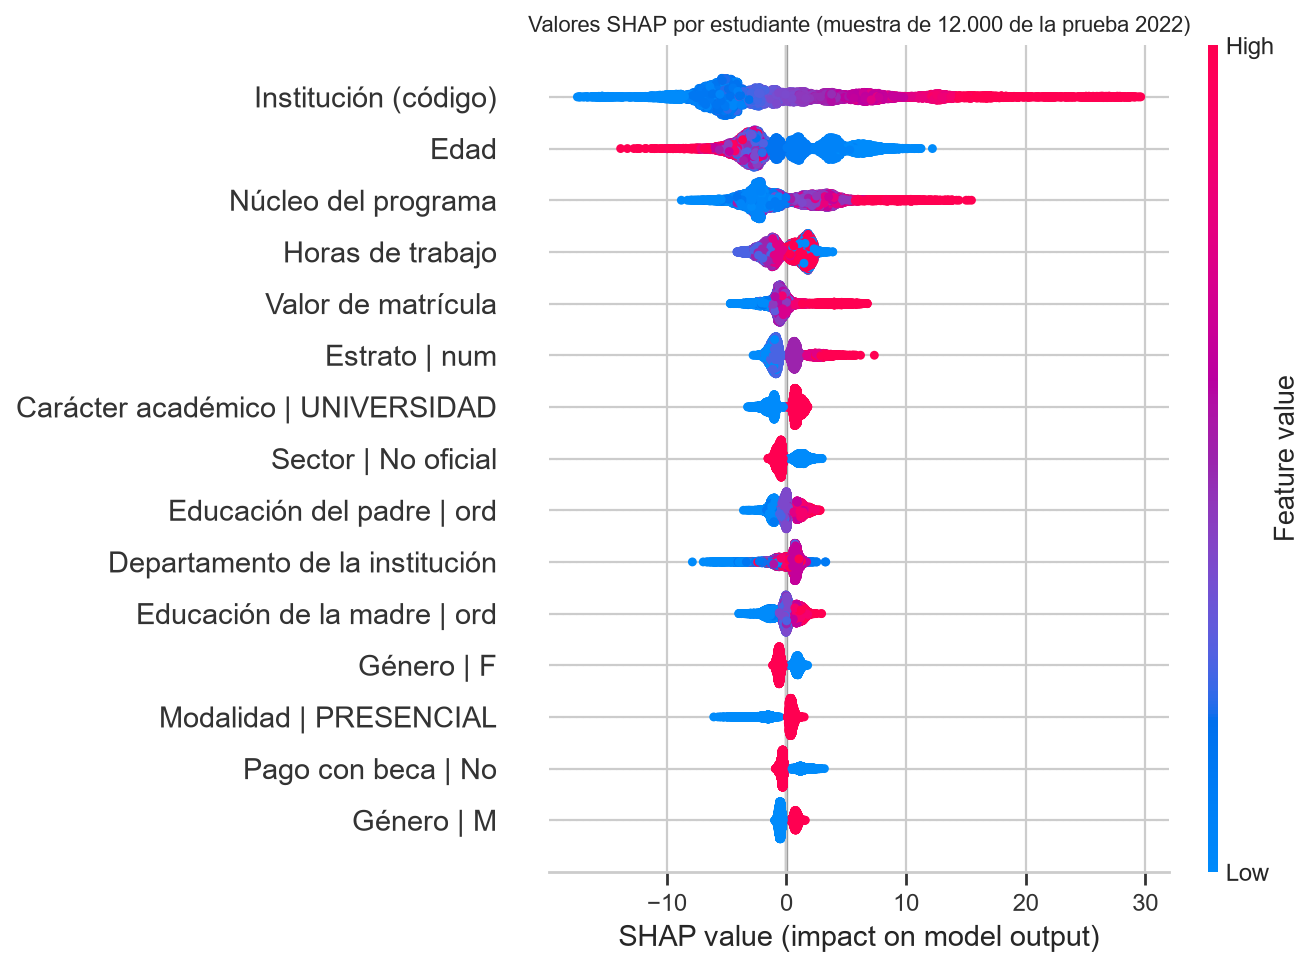

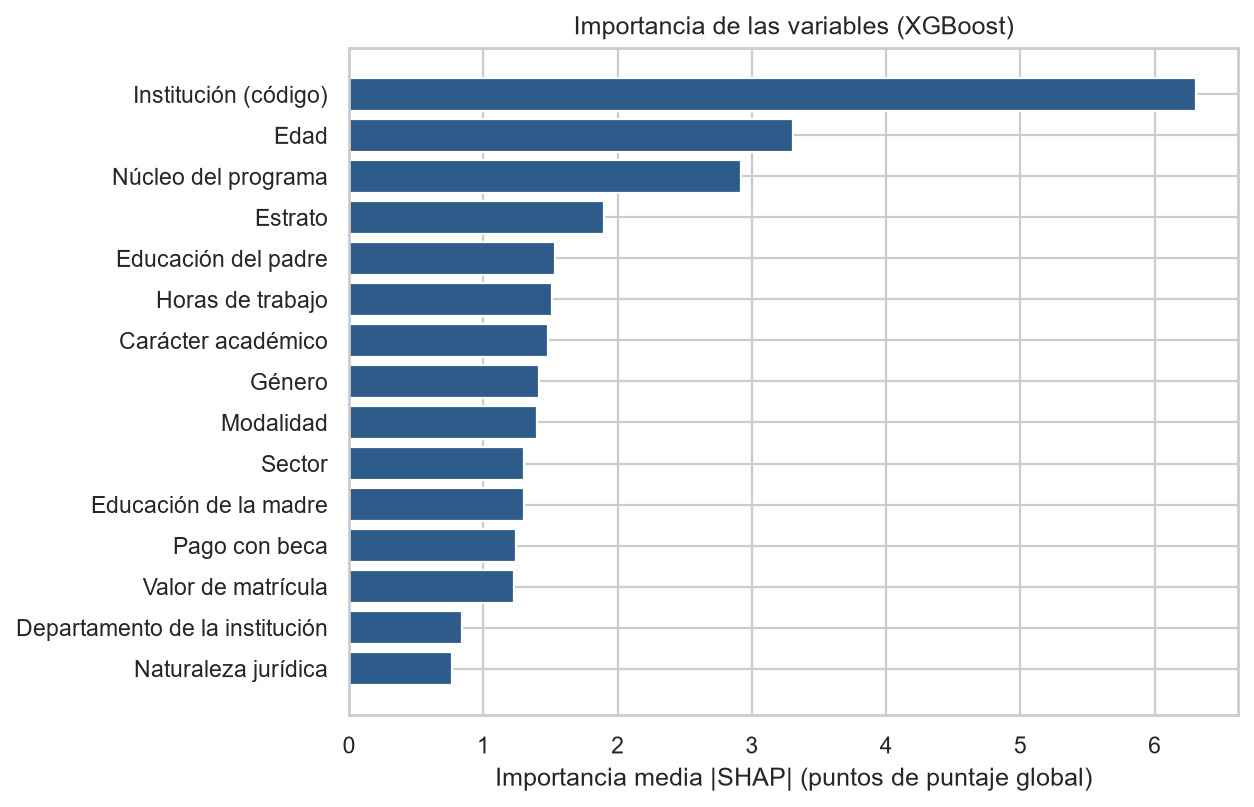

In [9]:
display(pd.read_csv(T / "mod_shap_importancia.csv").round(3))
display(Image(F / "mod_shap_resumen.png", width=700))
display(Image(F / "mod_shap_importancia.png", width=700))

## 8. Equidad por género y región, y criterios de éxito

In [10]:
display(pd.read_csv(T / "mod_equidad.csv").round(3))
display(pd.read_csv(T / "mod_criterios_exito.csv"))

,modelo,variable,grupo,n,pct_bajo_desempeno,recall25,dif_vs_global_pp,precision25,RMSE,error_medio,cumple_10pp,recall_global
0,XGBoost,Género,F,112654,26.351,0.584,7.438,0.498,17.815,-0.069,True,0.509
1,XGBoost,Género,M,80693,21.732,0.384,-12.592,0.496,19.583,0.328,False,0.509
2,XGBoost,Región de la institución,Amazonía,931,35.661,0.702,19.239,0.474,17.550,-1.272,False,0.509
3,XGBoost,Región de la institución,Andina,142068,23.085,0.465,-4.449,0.484,18.731,0.335,True,0.509
4,XGBoost,Región de la institución,Caribe,30103,28.924,0.610,10.102,0.506,17.976,-0.636,False,0.509
5,XGBoost,Región de la institución,Orinoquía,939,20.660,0.253,-25.684,0.412,19.024,-1.850,False,0.509
6,XGBoost,Región de la institución,Pacífica,19315,26.876,0.618,10.896,0.558,18.347,-0.356,False,0.509
7,XGBoost (clasif.),Género,F,112654,26.351,0.572,5.937,0.505,NaN,NaN,True,0.513
8,XGBoost (clasif.),Género,M,80693,21.732,0.412,-10.051,0.490,NaN,NaN,False,0.513
9,XGBoost (clasif.),Región de la institución,Amazonía,931,35.661,0.693,18.014,0.472,NaN,NaN,False,0.513


,n,criterio,resultado,cumple
0,1,"RMSE ≤ 19,4 (≥ 5 % mejor que la mejor línea base)",18.57 (B3 = 20.46; mejora 9.2 %),True
1,2,"AUC-ROC ≥ 0,75",0.777 (ensamble de regresión); 0.779 (XGBoost ...,True
2,3,"Recall ≥ 0,50 al alertar al 25 %",0.509 (ensamble); 0.513 (XGBoost (clasif.)),True
3,4,|RMSE de validación − RMSE de prueba| ≤ 10 % d...,validación 18.51 vs prueba 18.57: 0.3 % (insti...,True
4,5,Equidad: recall por género y región a ±10 pp d...,género: máx 12.6 pp; regiones con n ≥ 1.000: m...,False
5,6,Factores explicables y coherentes con el EDA,"Top-5 SHAP: Institución (código), Edad, Núcleo...",NaN


## 9. Reejecución completa (opcional)

Las dos celdas siguientes reproducen el entrenamiento completo y el análisis final. En Colab (CPU) el primero tarda del orden de 1,5–2 h; conviene activar una sesión con más memoria y mantener la pestaña abierta.

In [11]:
CORRER_ENTRENAMIENTO_COMPLETO = False
if CORRER_ENTRENAMIENTO_COMPLETO:
    !python -u src/08_modelado_entrenamiento.py

In [12]:
CORRER_ANALISIS_FINAL = False
if CORRER_ANALISIS_FINAL:
    !python -u src/09_inferencia_ablacion_shap.py